In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Configuración visual
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [2]:
# 0. CARGAR DATASET
# =======================================
# df = pd.read_csv("../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv")
df = pd.read_csv("../data_ready/COLLECT_COMP_dataset_treated.csv")

In [4]:
df

,CNTSCHID,CNTSTUID,STRATUM,BOOKID,RDESIGN,RCORE_TEST,RCORE_PERF,RS1_LEV,RS1_TEST,RCO1S_PERF,...,PV2SCIC,PV3SCIC,PV4SCIC,PV5SCIC,PV6SCIC,PV7SCIC,PV8SCIC,PV9SCIC,PV10SCIC,VER_DAT
0,60400034.0,60400002.0,PER01,Form 5,Design A (Stage1 then Stage2),Testlet 1,Low Level,Low,Testlet 14,Low Level,...,384.275,365.352,310.953,375.097,302.405,346.531,398.469,405.563,364.602,02MAY23:13:48:32
1,60400267.0,60400006.0,PER02,Form 15,Not used,Not used,Not used,Not used,Not used,Not used,...,408.801,419.913,328.540,352.137,371.997,384.288,385.746,338.499,358.010,02MAY23:13:48:33
2,60400224.0,60400008.0,PER01,Form 43,Not used,Not used,Not used,Not used,Not used,Not used,...,264.028,274.269,244.464,255.180,336.813,311.251,384.335,304.553,315.926,02MAY23:13:48:32
3,60400187.0,60400010.0,PER02,Form 4,Design A (Stage1 then Stage2),Testlet 1,Medium Level,Low,Testlet 14,Low Level,...,318.274,306.316,326.937,286.273,302.026,359.725,339.249,315.577,372.093,02MAY23:13:48:33
4,60400102.0,60400011.0,PER03,Form 24,Not used,Not used,Not used,Not used,Not used,Not used,...,419.836,462.336,393.296,396.027,415.945,422.710,411.513,431.318,400.626,02MAY23:13:48:33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6963,60400176.0,60409527.0,PER01,Form 44,Not used,Not used,Not used,Not used,Not used,Not used,...,409.846,423.159,384.212,427.170,413.777,383.592,327.241,393.202,463.055,02MAY23:13:48:32
6964,60400010.0,60409529.0,PER02,Form 9,Design A (Stage1 then Stage2),Testlet 3,Medium Level,High,Testlet 13,Low Level,...,416.026,402.931,367.748,420.649,398.087,363.265,436.983,434.046,362.291,02MAY23:13:48:33
6965,60400277.0,60409531.0,PER03,Form 8,Design B (Stage2 then Stage1),Testlet 5,Medium Level,High,Testlet 12,Medium Level,...,446.015,434.848,451.765,448.430,455.609,434.954,487.241,410.435,493.333,02MAY23:13:48:34
6966,60400177.0,60409533.0,PER02,Form 22,Not used,Not used,Not used,Not used,Not used,Not used,...,401.932,419.569,403.357,409.057,408.815,427.045,443.615,421.701,420.300,02MAY23:13:48:33


In [3]:
pv_cols = [col for col in df.columns if col.startswith("PV")]
print(pv_cols)

['PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH', 'PV10MATH', 'PV1READ', 'PV2READ', 'PV3READ', 'PV4READ', 'PV5READ', 'PV6READ', 'PV7READ', 'PV8READ', 'PV9READ', 'PV10READ', 'PV1SCIE', 'PV2SCIE', 'PV3SCIE', 'PV4SCIE', 'PV5SCIE', 'PV6SCIE', 'PV7SCIE', 'PV8SCIE', 'PV9SCIE', 'PV10SCIE', 'PV1MCCR', 'PV2MCCR', 'PV3MCCR', 'PV4MCCR', 'PV5MCCR', 'PV6MCCR', 'PV7MCCR', 'PV8MCCR', 'PV9MCCR', 'PV10MCCR', 'PV1MCQN', 'PV2MCQN', 'PV3MCQN', 'PV4MCQN', 'PV5MCQN', 'PV6MCQN', 'PV7MCQN', 'PV8MCQN', 'PV9MCQN', 'PV10MCQN', 'PV1MCSS', 'PV2MCSS', 'PV3MCSS', 'PV4MCSS', 'PV5MCSS', 'PV6MCSS', 'PV7MCSS', 'PV8MCSS', 'PV9MCSS', 'PV10MCSS', 'PV1MCUD', 'PV2MCUD', 'PV3MCUD', 'PV4MCUD', 'PV5MCUD', 'PV6MCUD', 'PV7MCUD', 'PV8MCUD', 'PV9MCUD', 'PV10MCUD', 'PV1MPEM', 'PV2MPEM', 'PV3MPEM', 'PV4MPEM', 'PV5MPEM', 'PV6MPEM', 'PV7MPEM', 'PV8MPEM', 'PV9MPEM', 'PV10MPEM', 'PV1MPFS', 'PV2MPFS', 'PV3MPFS', 'PV4MPFS', 'PV5MPFS', 'PV6MPFS', 'PV7MPFS', 'PV8MPFS', 'PV9MPFS', 'PV10MPFS', 

In [4]:
# 1. ESTADÍSTICAS DESCRIPTIVAS GENERALES
# =======================================
print("="*50)
print("RESUMEN ESTADÍSTICO DEL DATASET")
print("="*50)

# Asumiendo que tu dataset se llama 'df'
print(f"Dimensiones del dataset: {df.shape}")
print(f"Total de estudiantes: {df.shape[0]}")
print(f"Total de variables: {df.shape[1]}")

# Tipos de variables
print("\nTipos de variables:")
print(df.dtypes.value_counts())

RESUMEN ESTADÍSTICO DEL DATASET
Dimensiones del dataset: (6968, 4942)
Total de estudiantes: 6968
Total de variables: 4942

Tipos de variables:
float64    2694
object     2237
int64        11
Name: count, dtype: int64


In [5]:
# 2. ANÁLISIS DE MISSING VALUES
# ==============================
def analyze_missing_values(df):
    """Análisis detallado de valores faltantes"""
    missing = pd.DataFrame({
        'Variable': df.columns,
        'N_Missing': df.isnull().sum(),
        'Pct_Missing': (df.isnull().sum() / len(df)) * 100
    })
    missing = missing[missing['N_Missing'] > 0].sort_values('Pct_Missing', ascending=False)
    
    # Visualización
    if len(missing) > 0:
        plt.figure(figsize=(12, 6))
        plt.barh(missing['Variable'][:20], missing['Pct_Missing'][:20])
        plt.xlabel('Porcentaje de valores faltantes')
        plt.title('Top 20 Variables con Valores Faltantes')
        plt.tight_layout()
        plt.show()
    
    return missing

missing_analysis = analyze_missing_values(df)
print(f"\nVariables con valores faltantes: {len(missing_analysis)}")


Variables con valores faltantes: 0


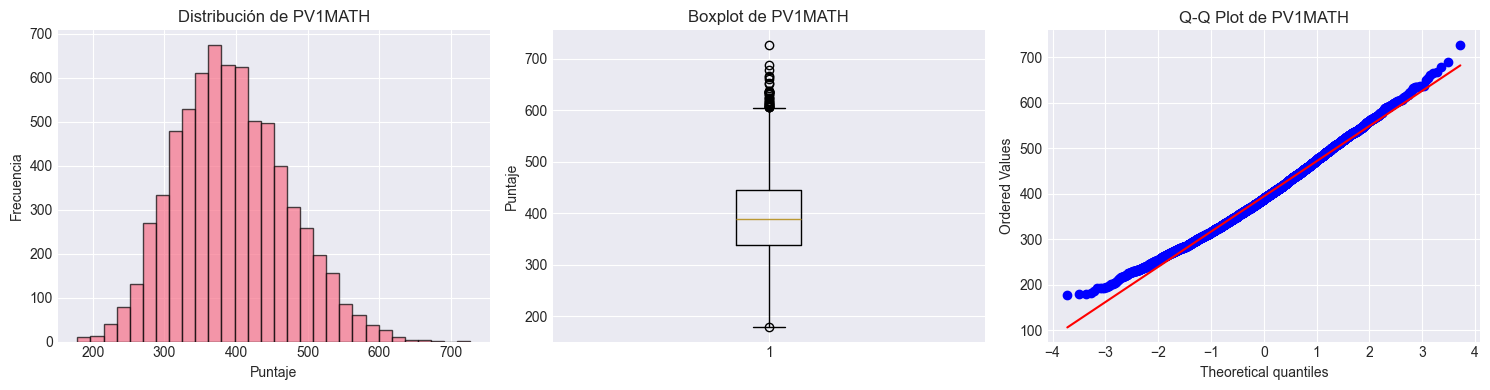


Estadísticas para PV1MATH:
count    6968.000000
mean      393.943331
std        77.603134
min       178.146000
25%       338.374250
50%       388.894000
75%       444.998000
max       727.576000
Name: PV1MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9933, p-value=0.0000


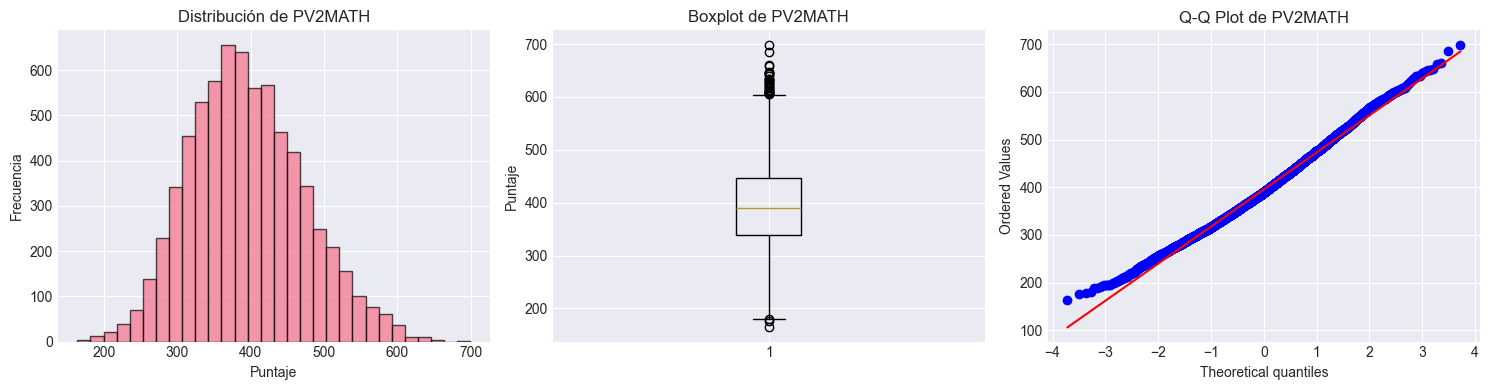


Estadísticas para PV2MATH:
count    6968.000000
mean      395.204718
std        77.990693
min       163.967000
25%       339.633250
50%       389.403500
75%       446.056500
max       699.225000
Name: PV2MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9930, p-value=0.0000


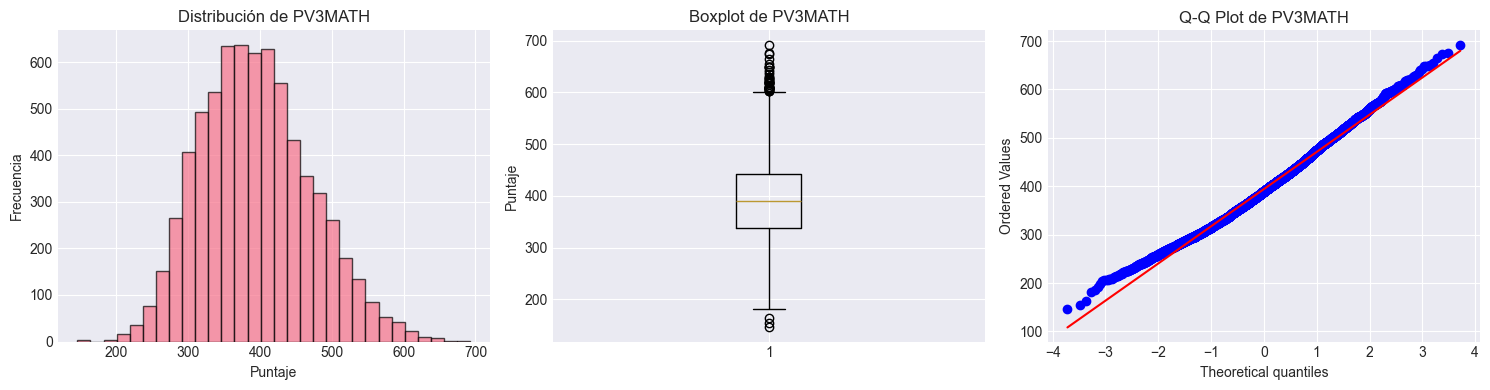


Estadísticas para PV3MATH:
count    6968.000000
mean      394.055898
std        77.086754
min       145.529000
25%       337.090000
50%       389.222000
75%       443.041000
max       692.668000
Name: PV3MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9918, p-value=0.0000


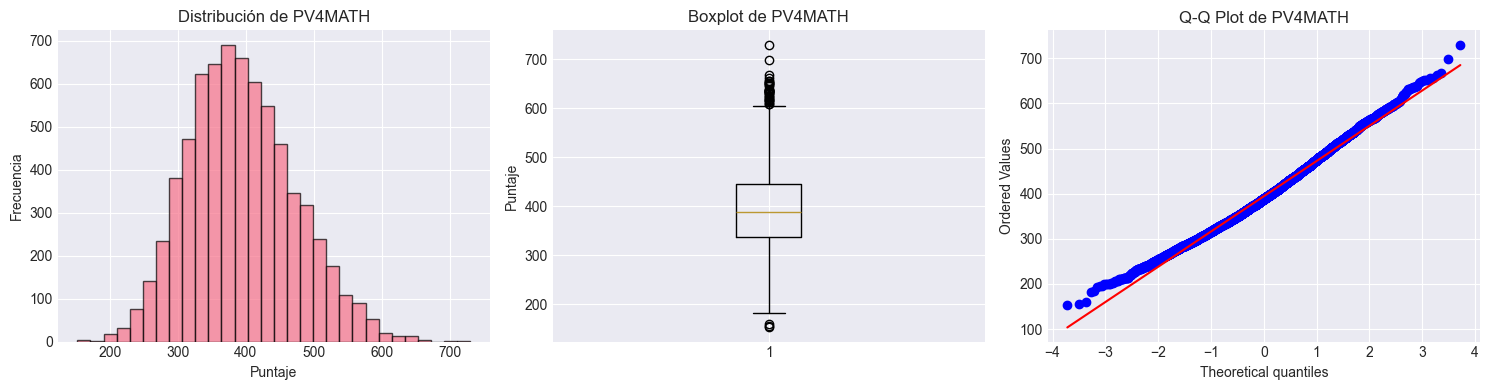


Estadísticas para PV4MATH:
count    6968.000000
mean      394.211655
std        78.392792
min       152.297000
25%       337.419000
50%       388.439500
75%       445.279500
max       730.356000
Name: PV4MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9925, p-value=0.0000


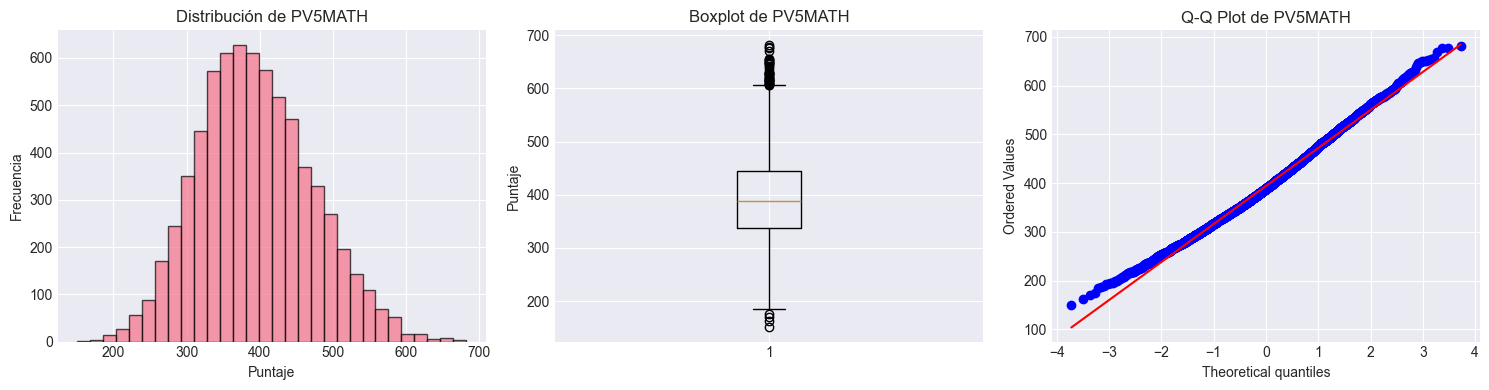


Estadísticas para PV5MATH:
count    6968.000000
mean      394.157008
std        78.160911
min       150.438000
25%       338.285250
50%       388.581000
75%       445.251250
max       682.276000
Name: PV5MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9948, p-value=0.0000


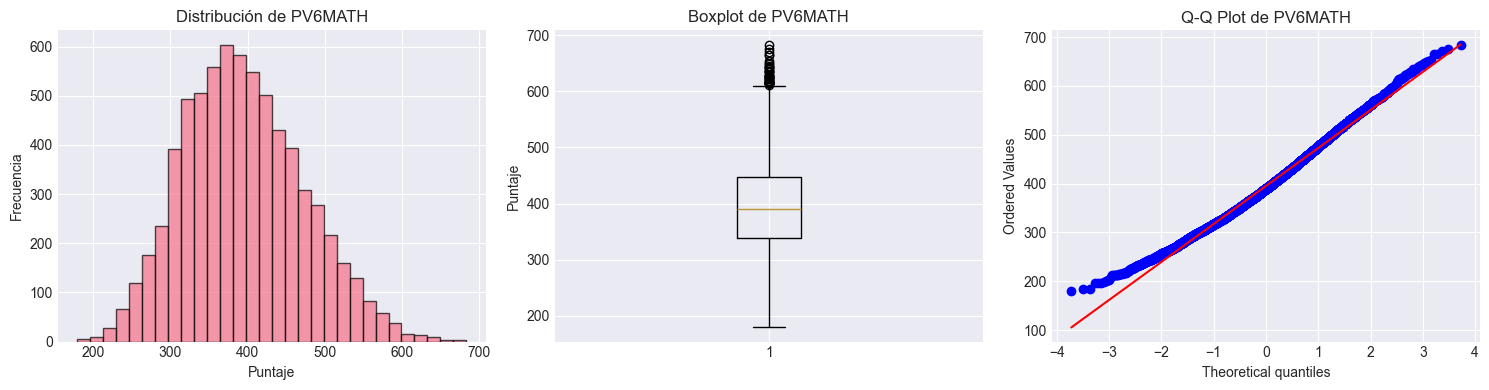


Estadísticas para PV6MATH:
count    6968.000000
mean      394.928204
std        78.135409
min       179.141000
25%       337.755750
50%       389.553000
75%       446.717000
max       683.411000
Name: PV6MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9914, p-value=0.0000


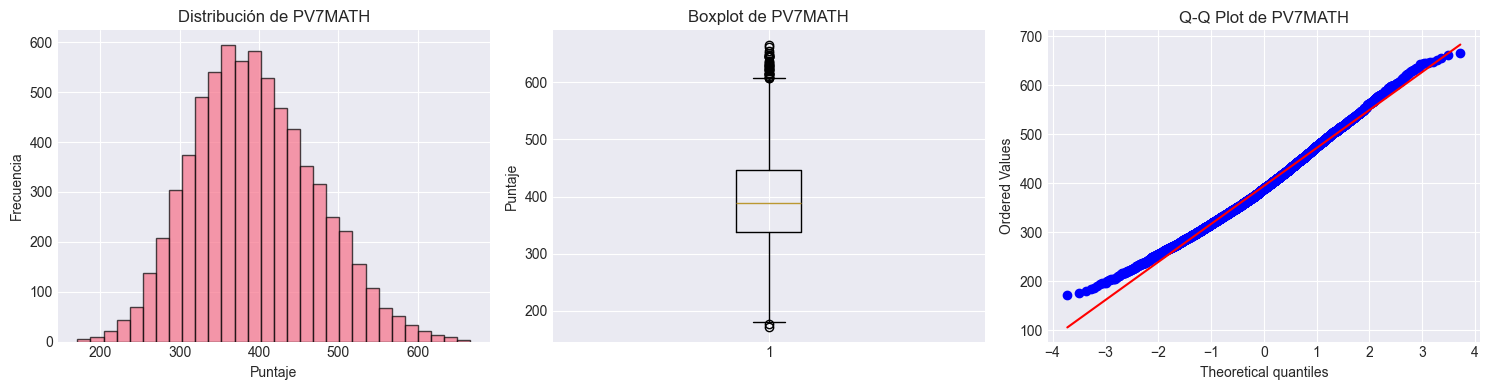


Estadísticas para PV7MATH:
count    6968.000000
mean      394.505181
std        77.887028
min       171.041000
25%       338.713750
50%       389.072500
75%       445.989500
max       666.145000
Name: PV7MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9944, p-value=0.0000


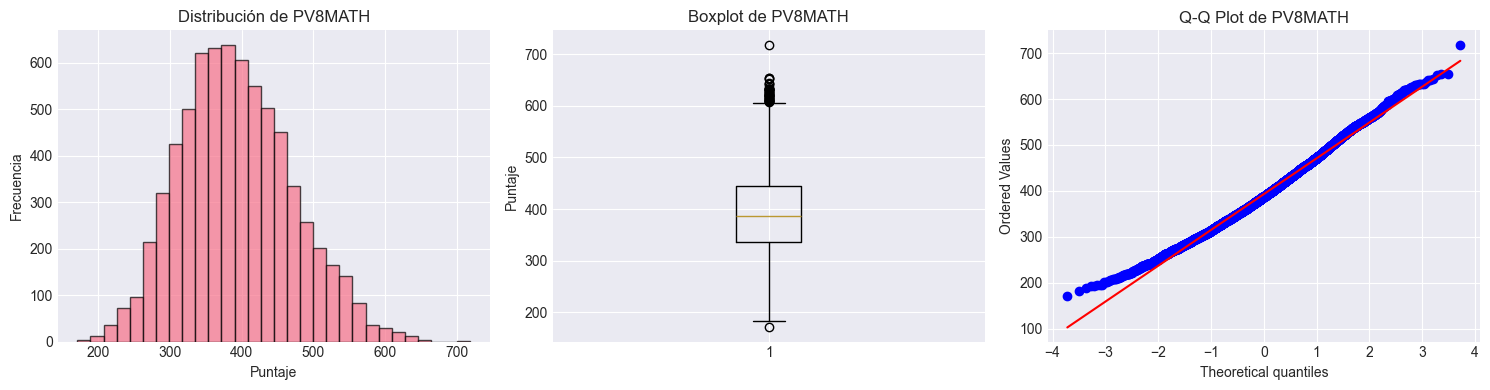


Estadísticas para PV8MATH:
count    6968.000000
mean      393.045211
std        78.258666
min       170.936000
25%       336.920250
50%       387.549000
75%       444.601000
max       718.646000
Name: PV8MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9928, p-value=0.0000


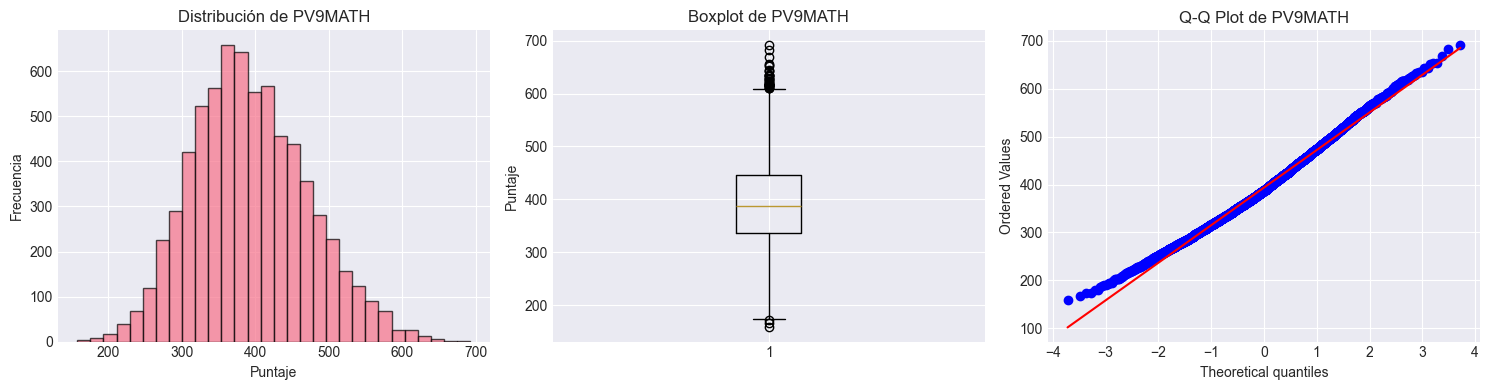


Estadísticas para PV9MATH:
count    6968.000000
mean      393.648968
std        78.733761
min       158.140000
25%       337.237750
50%       387.633000
75%       446.125750
max       692.555000
Name: PV9MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9934, p-value=0.0000


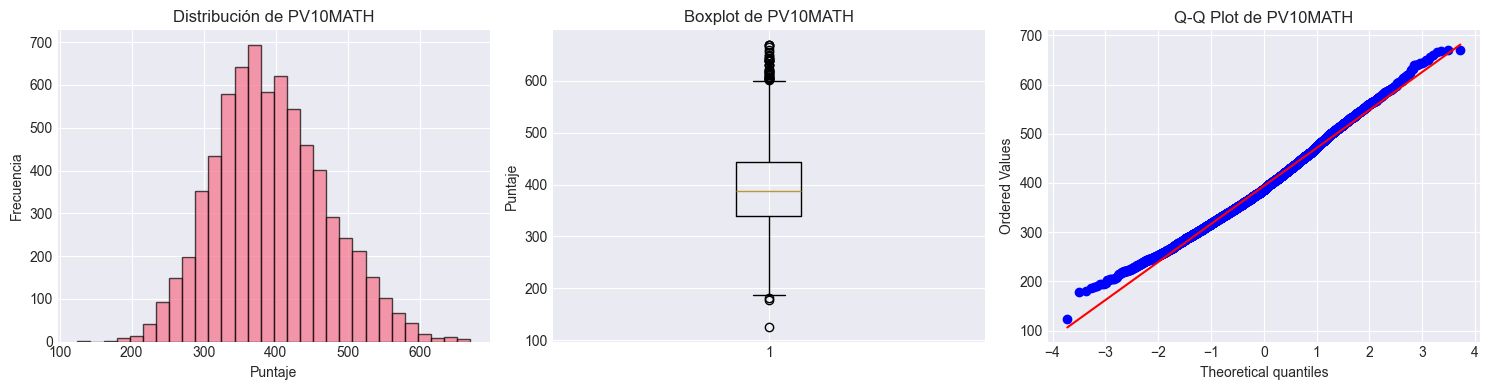


Estadísticas para PV10MATH:
count    6968.000000
mean      393.825488
std        77.473479
min       124.510000
25%       339.178500
50%       386.981500
75%       444.084750
max       670.232000
Name: PV10MATH, dtype: float64
Test de Shapiro-Wilk: estadístico=0.9928, p-value=0.0000


In [ ]:
# 3. ANÁLISIS DE LA VARIABLE OBJETIVO (Rendimiento Académico)
# ===========================================================
# En PISA, típicamente son los plausible values de matemáticas, lectura y ciencias
# rendimiento_vars = ['PV1MATH', 'PV1READ', 'PV1SCIE']  # Ajusta según tus variables

# MATEMATICAS
rendimiento_vars = ['PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH', 'PV10MATH']
# rendimiento_vars = ['PV1READ', 'PV2READ', 'PV3READ', 'PV4READ', 'PV5READ', 'PV6READ', 'PV7READ', 'PV8READ', 'PV9READ', 'PV10READ']
# 

for var in rendimiento_vars:
    if var in df.columns:
        plt.figure(figsize=(15, 4))
        
        # Histograma
        plt.subplot(1, 3, 1)
        plt.hist(df[var].dropna(), bins=30, edgecolor='black', alpha=0.7)
        plt.title(f'Distribución de {var}')
        plt.xlabel('Puntaje')
        plt.ylabel('Frecuencia')
        
        # Boxplot
        plt.subplot(1, 3, 2)
        plt.boxplot(df[var].dropna())
        plt.title(f'Boxplot de {var}')
        plt.ylabel('Puntaje')
        
        # Q-Q Plot para normalidad
        plt.subplot(1, 3, 3)
        stats.probplot(df[var].dropna(), dist="norm", plot=plt)
        plt.title(f'Q-Q Plot de {var}')
        
        plt.tight_layout()
        plt.show()
        
        # Estadísticas
        print(f"\nEstadísticas para {var}:")
        print(df[var].describe())
        
        # Test de normalidad
        stat, p_value = stats.shapiro(df[var].dropna().sample(min(5000, len(df[var].dropna()))))
        print(f"Test de Shapiro-Wilk: estadístico={stat:.4f}, p-value={p_value:.4f}")

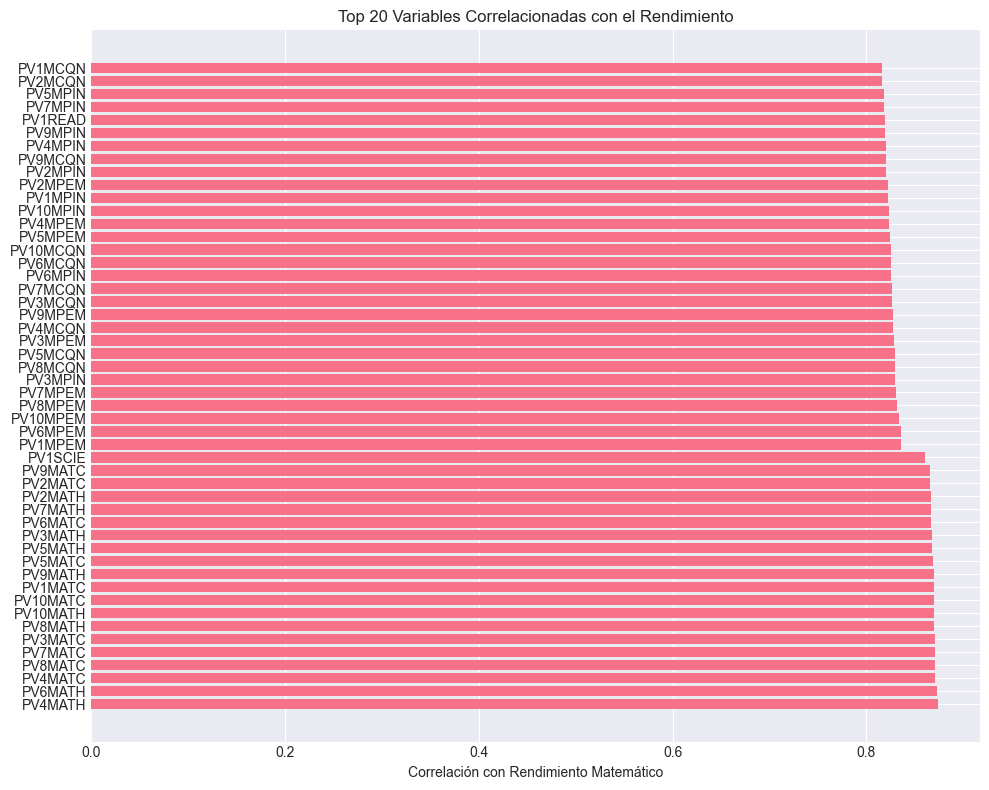

In [9]:
# 4. MATRIZ DE CORRELACIÓN INICIAL
# =================================
# Excluir columnas que contengan "PV" en el nombre
# df_no_pv = df.loc[:, ~df.columns.str.contains("PV", case=False)]

# Seleccionar variables numéricas para correlación
numeric_vars = df.select_dtypes(include=[np.number]).columns.tolist()

# Calcular correlación con el rendimiento
if 'PV1MATH' in df.columns:  # Usando matemáticas como ejemplo
    correlations = df[numeric_vars].corr()['PV1MATH'].sort_values(ascending=False)
    
    # Top 20 variables más correlacionadas
    top_correlations = correlations[1:51]  # Excluir la autocorrelación
    
    plt.figure(figsize=(10, 8))
    plt.barh(range(len(top_correlations)), top_correlations.values)
    plt.yticks(range(len(top_correlations)), top_correlations.index)
    plt.xlabel('Correlación con Rendimiento Matemático')
    plt.title('Top 20 Variables Correlacionadas con el Rendimiento')
    plt.tight_layout()
    plt.show()

In [23]:
df['SCHLTYPE']

0                    Public
1                    Public
2                    Public
3                    Public
4       Private independent
               ...         
6963                 Public
6964                 Public
6965    Private independent
6966                 Public
6967                 Public
Name: SCHLTYPE, Length: 6968, dtype: object

<Figure size 1000x600 with 0 Axes>

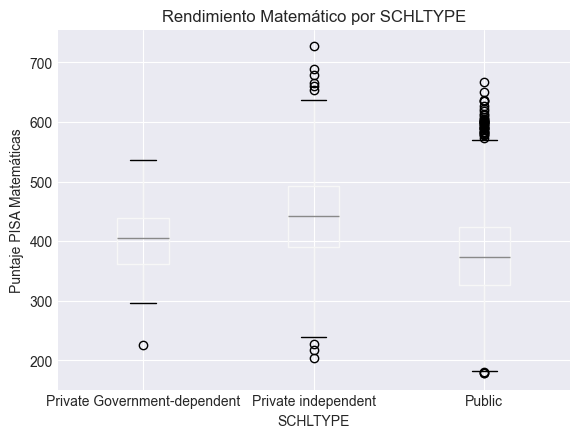


ANOVA para SCHLTYPE: F=467.8729, p-value=0.0000


<Figure size 1000x600 with 0 Axes>

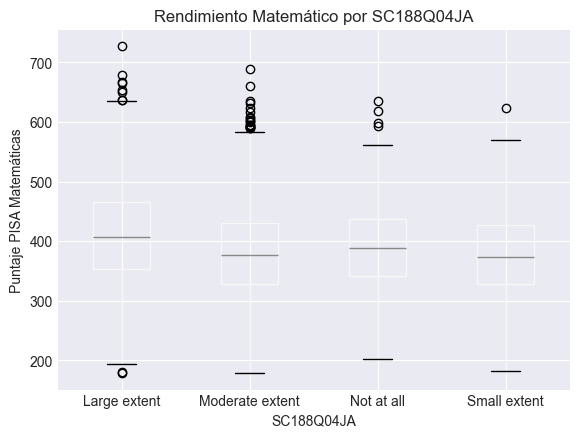


ANOVA para SC188Q04JA: F=83.5815, p-value=0.0000


In [29]:
# 5. ANÁLISIS POR GRUPOS CLAVE
# ============================
# Ejemplo: Análisis por tipo de escuela o nivel socioeconómico
# grouping_vars = ['SCHTYPE', 'ESCS_quintile']  # Ajusta según tus variables
grouping_vars = ['SCHLTYPE', 'SC188Q04JA']  # Ajusta según tus variables

for group_var in grouping_vars:
    if group_var in df.columns and 'PV1MATH' in df.columns:
        plt.figure(figsize=(10, 6))
        df.boxplot(column='PV1MATH', by=group_var)
        plt.title(f'Rendimiento Matemático por {group_var}')
        plt.suptitle('')  # Quitar el título automático
        plt.ylabel('Puntaje PISA Matemáticas')
        plt.show()
        
        # ANOVA de un factor
        # groups = [group for name, group in df.groupby(group_var)['PV1MATH'].apply(lambda x: x.dropna())]
        groups = [group.dropna() 
          for _, group in df.groupby(group_var)['PV1MATH']]
        f_stat, p_value = stats.f_oneway(*groups)
        print(f"\nANOVA para {group_var}: F={f_stat:.4f}, p-value={p_value:.4f}")